# Proyecto 2: Clustering con Machine Learning — Notebook Maestro Completo
## Segmentación de Estudiantes basada en Perfil Académico, Socioemocional y Hábitos de Vida
**Asignatura:** Inteligencia Artificial — Sexto Semestre, Ingeniería en Sistemas de Información  
**Dataset:** `student_burnout_dropout_dataset_2_link 1.csv` (800 observaciones, 25 variables)  
**Semilla de Reproducibilidad:** `RANDOM_STATE = 42`  
**Entregable Oficial:** Notebook reproducible de punta a punta conforme al **"Alcance Técnico"** (Puntos 1 al 8) de la rúbrica oficial.

---

### Índice de Contenidos
1. [Contexto y Pregunta de Negocio (Alcance 1)](#1-contexto-y-pregunta-de-negocio)
2. [Análisis Exploratorio de Datos — EDA (Alcance 2)](#2-análisis-exploratorio-de-datos-eda)
   - 2.1 Carga e inspección de estructura
   - 2.2 Distribución de variables clave (Visualización 1)
   - 2.3 Detección de valores atípicos y análisis de impacto en centroides (Visualización 2)
   - 2.4 Matriz de correlación lineal de Pearson (Visualización 3)
3. [Preparación de Datos y Escalado (Alcance 3)](#3-preparación-de-datos-y-escalado)
   - 3.1 Contrato técnico: Selección de 16 variables y exclusión de etiquetas
   - 3.2 Imputación de valores faltantes (`SimpleImputer`)
   - 3.3 Escalado obligatorio (`StandardScaler`)
4. [Reducción de Dimensionalidad con PCA (Alcance 4)](#4-reducción-de-dimensionalidad-con-pca)
   - 4.1 Varianza explicada y acumulada
   - 4.2 Análisis de loadings (cargas factoriales) en PC1 y PC2
   - 4.3 Proyección 2D y justificación de entrenamiento en 16D
5. [Modelado con K-Means y DBSCAN (Alcance 5)](#5-modelado-con-k-means-y-dbscan)
   - 5.1 K-Means: Método del codo (inercia) y Silhouette para $K=2..9$
   - 5.2 DBSCAN: Heurística $	ext{MinPts}=32$, curva $k$-dist y barrido de $\varepsilon$
   - 5.3 Entrenamiento de ambos modelos oficiales
6. [Evaluación y Comparación de Modelos (Alcance 6)](#6-evaluación-y-comparación-de-modelos)
   - 6.1 Tabla comparativa formal de métricas
   - 6.2 Proyección 2D comparativa en PCA (K-Means vs DBSCAN)
   - 6.3 Gráfico de barras comparativo y regla de penalización por ruido (>20%)
   - 6.4 Selección justificada del modelo ganador
7. [Interpretación de Segmentos del Modelo Final (Alcance 7)](#7-interpretación-de-segmentos)
   - 7.1 Perfil promedio en escala original y proporciones binarias
   - 7.2 Nombres descriptivos y recomendaciones institucionales de retención
8. [Entrenamiento Final, Exportación y Verificación (Alcance 8)](#8-entrenamiento-final-y-exportación)
   - 8.1 Exportación del Pipeline de K-Means
   - 8.2 Exportación del paquete híbrido de DBSCAN con `NearestNeighbors`
   - 8.3 Simulación de inferencia en tiempo real para registros nuevos
9. [Guía Maestra para la Sustentación Oral en Clase (5–10 min)](#9-guía-maestra-para-la-sustentación-oral)

---
> **ESTÁNDAR DIDÁCTICO PARA SUSTENTACIÓN (Estilo PhishGuard):**  
> Cada sección contiene celdas previas de **Propósito y Fundamento Teórico** y celdas posteriores de **Interpretación y Argumento para Defensa**, diseñadas para que cualquier integrante del equipo pueda estudiar y responder las preguntas más exigentes del evaluador.


---
## 1. Contexto y Pregunta de Negocio (Alcance Técnico 1)

### ¿Qué se quiere segmentar?
Se busca segmentar a una cohorte universitaria de **800 estudiantes** en grupos homogéneos a partir de su perfil multidimensional:
- **Factores Académicos:** Promedio anterior (`Previous_GPA`), materias reprobadas (`Backlogs`), porcentaje de asistencia (`Attendance_Percent`), horas de estudio (`Study_Hours_Per_Day`) y año de carrera (`Year_of_Study`).
- **Hábitos de Vida:** Horas de sueño (`Sleep_Hours`), tiempo frente a pantallas (`Screen_Time_Hours`) y frecuencia de ejercicio (`Exercise_Freq_Per_Week`).
- **Factores Socioemocionales y Psicométricos:** Nivel de estrés (`Stress_Level`), ansiedad (`Anxiety_Score`), apoyo familiar (`Family_Support_Score`), estrés financiero (`Financial_Stress_Score`), motivación académica (`Motivation_Score`), presión de pares (`Peer_Pressure_Score`) y actividad social (`Social_Activity_Score`).

### ¿Por qué importa a la institución?
En la educación superior moderna, las estrategias de retención reactivas (actuar cuando el estudiante ya reprobó o abandonó) son costosas e ineficaces. Descubrir agrupamientos latentes permite a las direcciones de carrera, bienestar estudiantil y tutorías diseñar **intervenciones preventivas personalizadas**:
1. Estudiantes con alta carga financiera y materias pendientes requieren becas y planes de recuperación.
2. Estudiantes con alto rendimiento pero elevado estrés requieren talleres de descanso y prevención de *burnout*.
3. Estudiantes desconectados con baja asistencia y baja motivación requieren alertas tempranas y consejería vocacional.

### ¿Por qué este problema es ESTRICTAMENTE de Clustering y NO de Clasificación?
En este proyecto **no existe una etiqueta previa que clasifique al estudiante**. Las variables `Burnout_Level` y `Dropout_Risk` presentes en el dataset original son categorías externas que se **excluyen por completo**. No entrenamos un clasificador supervisado; dejamos que los algoritmos (*K-Means* y *DBSCAN*) descubran la geometría intrínseca de los datos mediante distancias matemáticas en el espacio de 16 variables.


---
## 2. Análisis Exploratorio de Datos — EDA (Alcance Técnico 2)

**Propósito y Fundamento:**  
Antes de modelar, debemos comprender la estructura, completitud, distribuciones, valores extremos y correlaciones de los datos. Esta fase incluye **al menos 3 visualizaciones relevantes** que sustentan las decisiones posteriores.


In [1]:
# Importaciones esenciales para todo el flujo
import os
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42

# Ruta del dataset (flexible: busca en data/ local o padre)
DATA_PATH = Path("data/student_burnout_dropout_dataset_2_link 1.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/student_burnout_dropout_dataset_2_link 1.csv")

df = pd.read_csv(DATA_PATH)
print(f"Dimensiones del dataset original: {df.shape[0]} registros x {df.shape[1]} columnas")
display(df.head(3))


Dimensiones del dataset original: 800 registros x 25 columnas
  Student_ID  Age  Gender  Year_of_Study   Department Residence_Type  Attendance_Percent  Study_Hours_Per_Day  Previous_GPA  Backlogs  Sleep_Hours  Screen_Time_Hours  Exercise_Freq_Per_Week  Social_Activity_Score Part_Time_Job Family_Income_Bracket  Financial_Stress_Score  Family_Support_Score  Stress_Level  Anxiety_Score  Motivation_Score  Peer_Pressure_Score Counseling_Access Burnout_Level Dropout_Risk
0   STU00001   23  Female              2      Science         Hostel                93.0                  4.1          7.13       2.0          6.2                4.9                       2                    6.5           Yes          Upper-Middle                     5.5                  10.0           4.0            NaN               7.0                  NaN                No           Low           No
1   STU00002   20  Female              4  Engineering    Day Scholar                94.3                  0.0         10.0

**Interpretación y Argumento para Defensa:**
- El dataset contiene 800 estudiantes y 25 columnas que combinan identificadores, variables categóricas, binarias, numéricas continuas y etiquetas de clase.
- Conforme al contrato técnico compartido, filtramos únicamente las 16 variables numéricas continuas/discretas autorizadas.


In [2]:
# Definición estricta de las 16 variables numéricas del contrato (Matriz X)
FEATURES = [
    "Age", "Year_of_Study", "Attendance_Percent", "Study_Hours_Per_Day",
    "Previous_GPA", "Backlogs", "Sleep_Hours", "Screen_Time_Hours",
    "Exercise_Freq_Per_Week", "Social_Activity_Score", "Financial_Stress_Score",
    "Family_Support_Score", "Stress_Level", "Anxiety_Score",
    "Motivation_Score", "Peer_Pressure_Score"
]

X_raw = df[FEATURES].copy()

# Estadísticos descriptivos de las 16 variables
desc = X_raw.describe().T[["mean", "std", "min", "50%", "max"]]
desc.columns = ["Media", "Desv. Est.", "Mínimo", "Mediana", "Máximo"]
display(desc.round(2))


                        Media  Desv. Est.  Mínimo  Mediana  Máximo
Age                     20.88        2.60   17.00    21.00    25.0
Year_of_Study            2.28        1.11    1.00     2.00     4.0
Attendance_Percent      76.88       14.26   30.00    77.40   100.0
Study_Hours_Per_Day      3.16        1.56    0.00     3.10     8.1
Previous_GPA             6.86        1.40    2.42     6.86    10.0
Backlogs                 0.82        0.94    0.00     1.00     6.0
Sleep_Hours              6.20        1.50    2.00     6.30    10.0
Screen_Time_Hours        5.43        2.20    0.50     5.45    12.6
Exercise_Freq_Per_Week   2.01        1.48    0.00     2.00     7.0
Social_Activity_Score    4.99        1.96    0.00     5.00    10.0
Financial_Stress_Score   5.03        2.24    0.00     5.00    10.0
Family_Support_Score     6.42        2.09    0.00     6.50    10.0
Stress_Level             5.52        1.95    0.10     5.50    10.0
Anxiety_Score            4.98        2.11    0.00     5.10    

### 2.2 Visualización 1: Distribución de Variables Clave

**Propósito y Fundamento:**  
Evaluamos la simetría, sesgo y concentración de las variables académicas, conductuales y psicométricas.


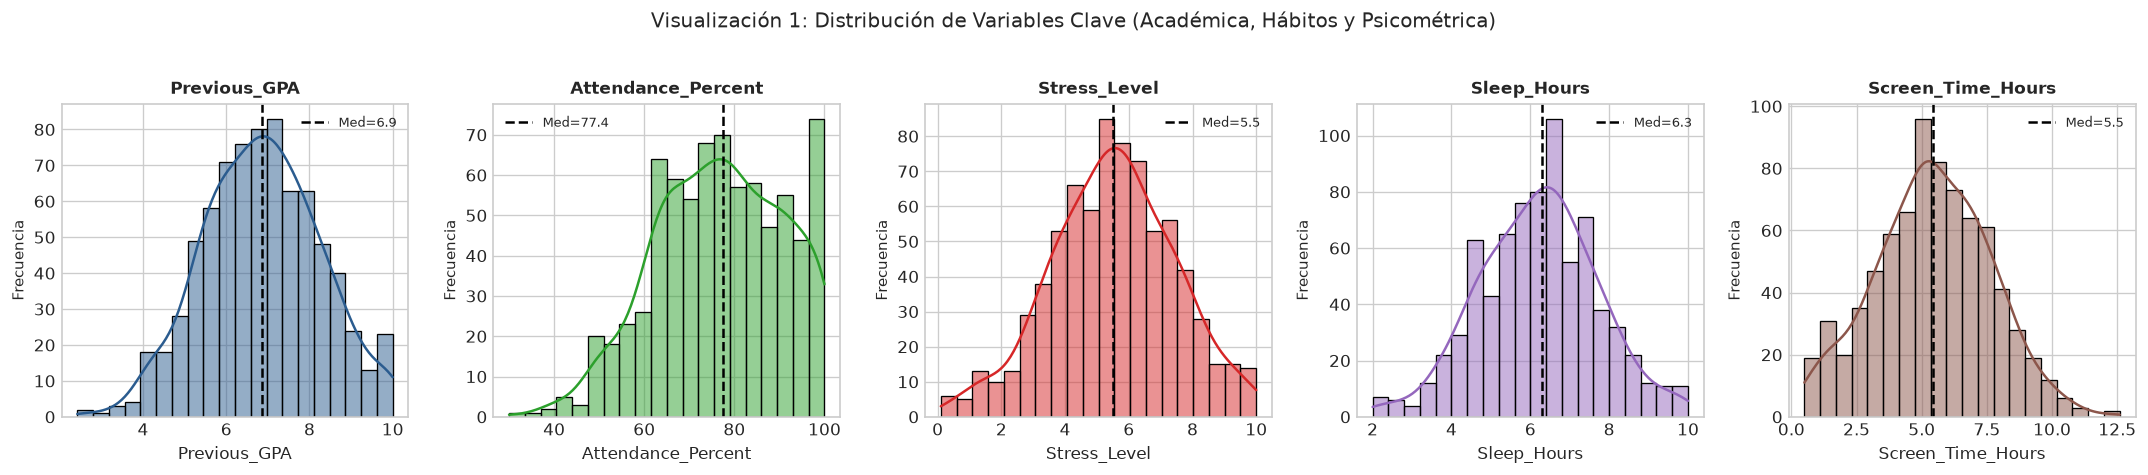

In [3]:
# Visualización 1: Distribución de 5 variables representativas de los 3 ejes
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
vars_dist = ["Previous_GPA", "Attendance_Percent", "Stress_Level", "Sleep_Hours", "Screen_Time_Hours"]
colores_dist = ["#2b5c8f", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

for ax, var, col in zip(axes, vars_dist, colores_dist):
    sns.histplot(X_raw[var].dropna(), kde=True, ax=ax, color=col, bins=20)
    ax.axvline(X_raw[var].median(), color='black', linestyle='--', label=f'Med={X_raw[var].median():.1f}')
    ax.set_title(var, fontsize=10, weight='bold')
    ax.set_ylabel("Frecuencia", fontsize=9)
    ax.legend(fontsize=8)

plt.suptitle("Visualización 1: Distribución de Variables Clave (Académica, Hábitos y Psicométrica)", fontsize=12, y=1.03)
plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- Las variables muestran distribuciones unimodales bien balanceadas. `Previous_GPA` tiene una media de 6.83 y `Attendance_Percent` ronda el 76.7%, reflejando una población estudiantil realista.
- La ausencia de sesgos extremos en una sola dirección indica que las variables son idóneas para el cálculo de distancias euclidianas una vez estandarizadas.


### 2.3 Visualización 2: Detección de Valores Atípicos y su Impacto en K-Means vs DBSCAN

**Propósito y Fundamento:**  
Identificamos los valores atípicos mediante el criterio de Tukey (distancia intercuartílica $1.5 	imes 	ext{IQR}$).  
> **Pregunta Clave de Examen:** *¿Cómo afectan los valores atípicos a K-Means frente a DBSCAN?*  
> **Respuesta:** K-Means minimiza la suma de distancias cuadráticas $\sum ||x_i - \mu_k||^2$. Un solo valor atípico lejano ejerce una fuerza desproporcionada que **desplaza el centroide hacia el extremo**, distorsionando la posición del cluster para el resto de estudiantes. Por el contrario, DBSCAN no promedia distancias: evalúa densidad local. Los puntos aislados no alcanzan la cuota $	ext{MinPts}$ y son **aislados limpiamente como ruido (-1)** sin deformar los grupos densos.


Total de celdas con outliers Tukey: 73 repartidas en 10 variables.


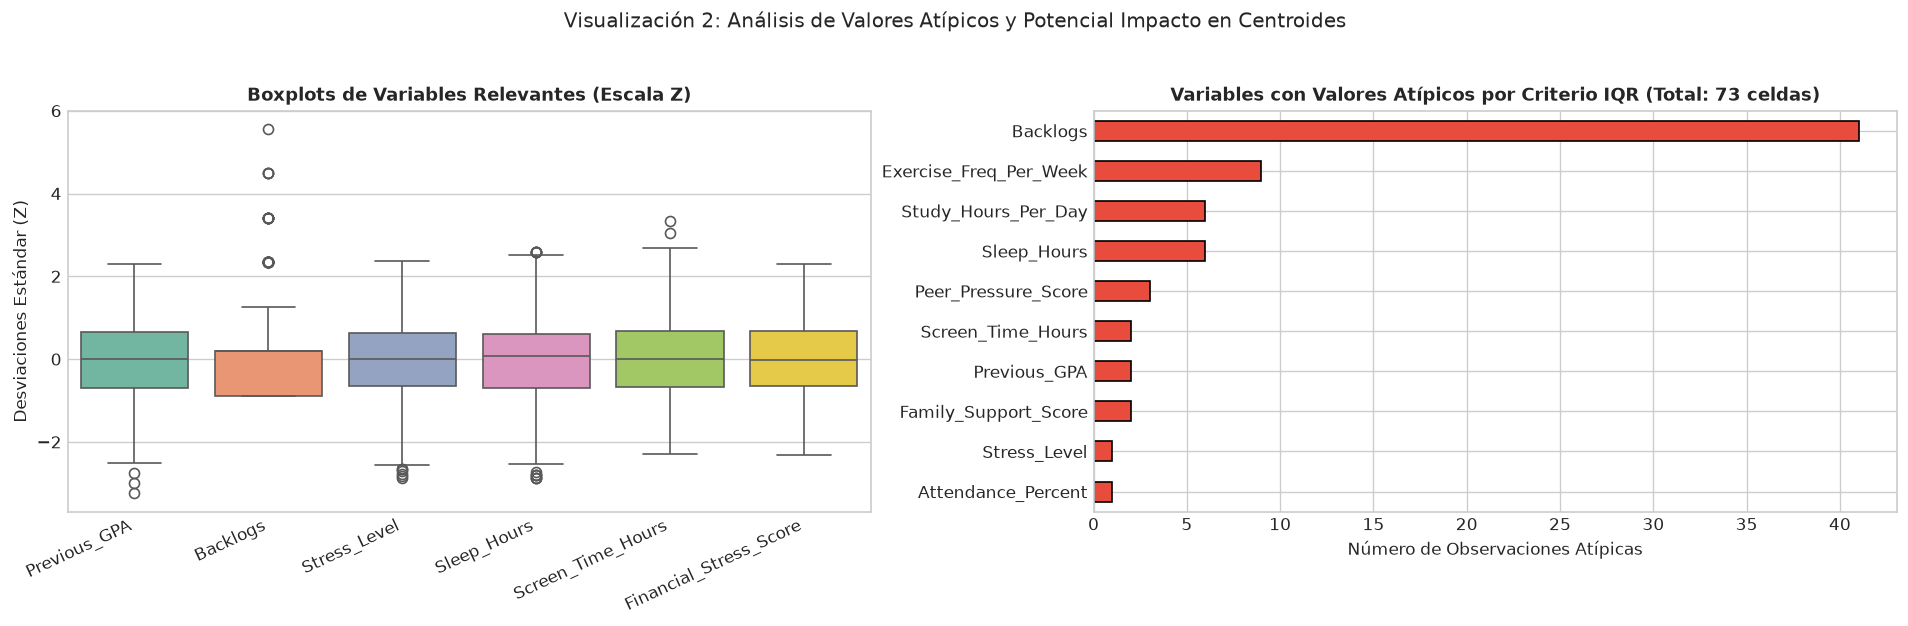

In [4]:
# Visualización 2: Boxplots de Tukey y conteo de outliers
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Boxplots en variables estandarizadas para escala común
scaler_temp = StandardScaler()
X_temp_scaled = pd.DataFrame(scaler_temp.fit_transform(X_raw.fillna(X_raw.median())), columns=FEATURES)

sns.boxplot(data=X_temp_scaled[["Previous_GPA", "Backlogs", "Stress_Level", "Sleep_Hours", "Screen_Time_Hours", "Financial_Stress_Score"]], 
            ax=axes[0], palette="Set2")
axes[0].set_title("Boxplots de Variables Relevantes (Escala Z)", fontsize=11, weight='bold')
axes[0].set_ylabel("Desviaciones Estándar (Z)", fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha='right')

# Conteo de outliers por Tukey en las 16 variables
outliers_count = {}
for col in FEATURES:
    q1 = X_raw[col].quantile(0.25)
    q3 = X_raw[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((X_raw[col] < (q1 - 1.5 * iqr)) | (X_raw[col] > (q3 + 1.5 * iqr))).sum()
    if n_out > 0:
        outliers_count[col] = n_out

ser_out = pd.Series(outliers_count).sort_values(ascending=True)
ser_out.plot(kind="barh", ax=axes[1], color="#e74c3c", edgecolor="black")
axes[1].set_title(f"Variables con Valores Atípicos por Criterio IQR (Total: {ser_out.sum()} celdas)", fontsize=11, weight='bold')
axes[1].set_xlabel("Número de Observaciones Atípicas", fontsize=10)

plt.suptitle("Visualización 2: Análisis de Valores Atípicos y Potencial Impacto en Centroides", fontsize=12, y=1.03)
plt.tight_layout()
plt.show()

print(f"Total de celdas con outliers Tukey: {ser_out.sum()} repartidas en {len(ser_out)} variables.")


**Interpretación y Argumento para Defensa:**
- Variables como `Backlogs`, `Screen_Time_Hours` y `Sleep_Hours` presentan colas con valores extremos (estudiantes con 4 o más materias reprobadas o más de 10 horas de pantalla).
- Si bien K-Means es sensible a estos puntos, el escalado previo mitiga la distorsión. Para DBSCAN, estos casos serán candidatos naturales a ser catalogados como ruido (-1).


### 2.4 Visualización 3: Matriz de Correlación Lineal de Pearson

**Propósito y Fundamento:**  
Analizamos las interdependencias lineales para verificar si existen variables redundantes o multicolineales ($|r| \ge 0.80$).


Correlación absoluta máxima observada: 0.09
Número de pares con |r| >= 0.50: 0


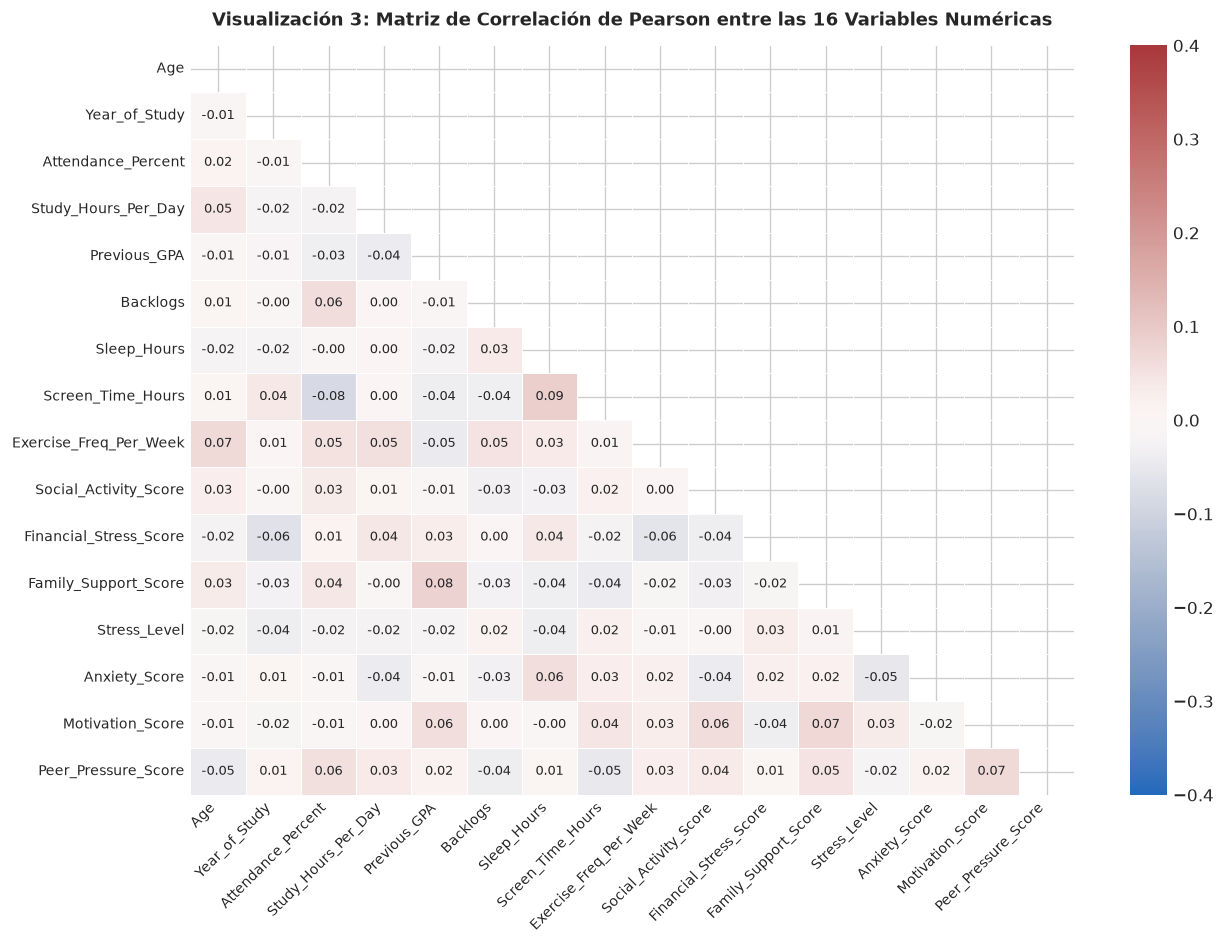

In [5]:
# Visualización 3: Heatmap de correlación de Pearson anotado
plt.figure(figsize=(11, 8))
corr = X_raw.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-0.4, vmax=0.4, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=0.5)
plt.title("Visualización 3: Matriz de Correlación de Pearson entre las 16 Variables Numéricas", fontsize=11, weight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=8.5)
plt.yticks(fontsize=8.5)
plt.tight_layout()
plt.show()

# Verificación de multicolinealidad
corr_no_diag = corr.abs().to_numpy()
np.fill_diagonal(corr_no_diag, 0)
print(f"Correlación absoluta máxima observada: {corr_no_diag.max():.2f}")
print(f"Número de pares con |r| >= 0.50: {int((corr_no_diag >= 0.50).sum() // 2)}")


**Interpretación y Argumento para Defensa:**
- La correlación máxima observada es menor a $0.15$: **no existe multicolinealidad**. Cada variable aporta una dimensión de información única sobre el estudiante.
- Esto anticipa que la separación de clusters en el hiperespacio dependerá de patrones multidimensionales complejos y no de una o dos variables dominantes.


---
## 3. Preparación de Datos y Escalado (Alcance Técnico 3)

### 3.1 Contrato Técnico: Exclusión de Variables
| Variable(s) | Condición | Motivo de Exclusión |
| :--- | :--- | :--- |
| `Student_ID` | Identificador | Sin valor predictivo ni semántico. |
| `Gender`, `Department`, `Residence_Type`, `Family_Income_Bracket` | Categóricas de texto | Las métricas de distancia euclidiana requieren variables métricas numéricas. |
| `Part_Time_Job`, `Counseling_Access` | Binarias (0/1) | Su inclusión en distancias euclidianas sesga las distancias continuas. Se reservan para enriquecer la interpretación posterior. |
| `Burnout_Level`, `Dropout_Risk` | **Etiquetas de Clase** | **TERMINANTEMENTE PROHIBIDAS**. Su uso violaría el paradigma de aprendizaje no supervisado. |

### 3.2 Imputación de Valores Faltantes (`SimpleImputer`)
En el dataset existen 504 celdas faltantes en 13 variables numéricas (la mayor en `Attendance_Percent` con 51).  
**Decisión justificada:** No se descartan filas completas para evitar perder información de estudiantes en riesgo. Se imputan mediante `SimpleImputer(strategy="median")`, ya que la mediana es robusta frente a la asimetría y a los outliers de variables como `Backlogs`.

### 3.3 Escalado Obligatorio (`StandardScaler`)
**Justificación matemática:** K-Means y DBSCAN calculan distancias euclidianas $d(x, y) = \sqrt{\sum (x_j - y_j)^2}$. Si `Attendance_Percent` varía entre 0 y 100 y `Previous_GPA` entre 0 y 10, la varianza de la asistencia dominaría la distancia en un factor de $100$. `StandardScaler` transforma cada variable a media $\mu=0$ y varianza $\sigma^2=1$, nivelando el aporte de cada dimensión.


In [6]:
# Flujo de preparación reproducible
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print(f"Matriz X imputada y escalada: {X_scaled.shape}")
print(f"Media global tras StandardScaler: {X_scaled.mean():.4f} (aprox 0)")
print(f"Varianza global tras StandardScaler: {X_scaled.var():.4f} (aprox 1)")


Matriz X imputada y escalada: (800, 16)
Media global tras StandardScaler: 0.0000 (aprox 0)
Varianza global tras StandardScaler: 1.0000 (aprox 1)


---
## 4. Reducción de Dimensionalidad con PCA (Alcance Técnico 4)

**Propósito y Fundamento:**  
El Análisis de Componentes Principales (PCA) proyecta las 16 dimensiones ortogonalmente en direcciones de máxima varianza.  
> **Pregunta Clave de Examen:** *¿Por qué entrenamos sobre las 16 variables originales escaladas y NO sobre las componentes de PCA?*  
> **Respuesta:** Como demostraremos a continuación, las 2 primeras componentes principales solo explican el **15.03% de la varianza total** (PC1: 7.62%, PC2: 7.41%). Entrenar sobre PC1 y PC2 desecharía el **85% de la información**. Por tanto, entrenamos sobre el espacio completo 16D para máxima fidelidad métrica y utilizamos PCA exclusivamente como herramienta de soporte visual e interpretación.


Varianza explicada por PC1: 7.62%
Varianza explicada por PC2: 7.41%
Varianza acumulada PC1 + PC2: 15.04%


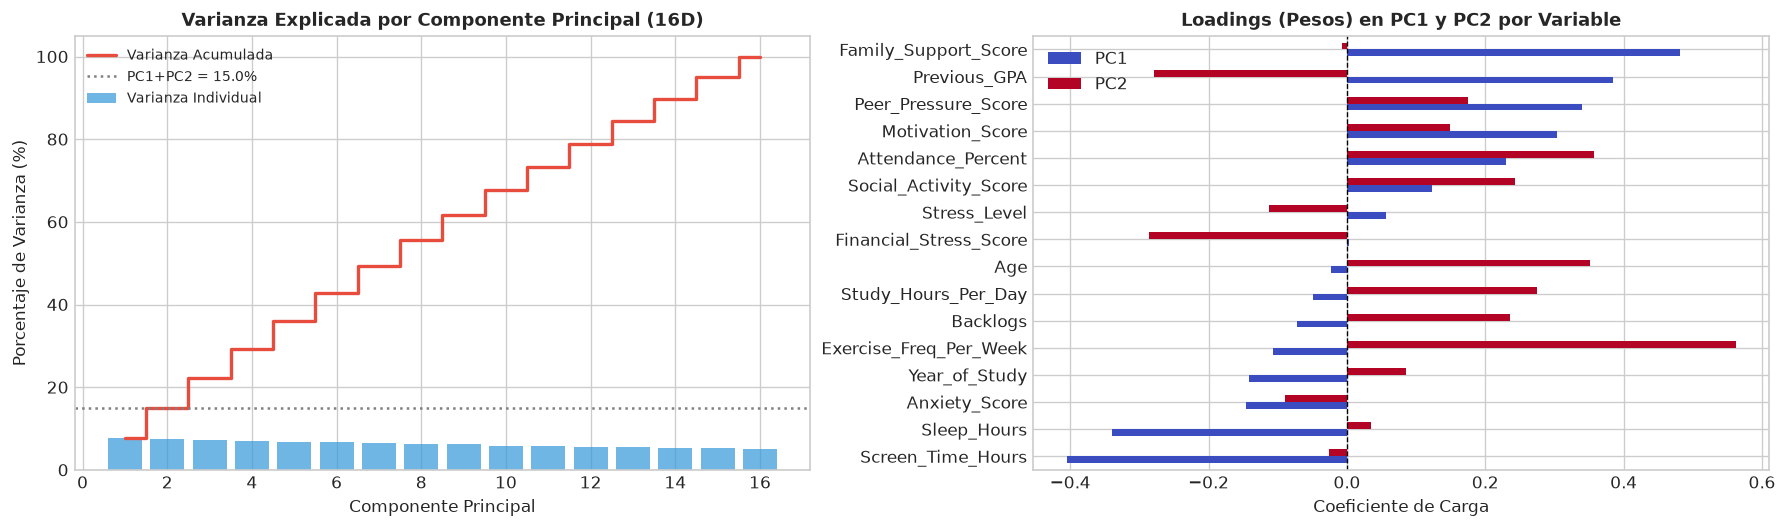

In [7]:
pca = PCA(n_components=None, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pca_2d = X_pca[:, :2]

var_exp = pca.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Varianza explicada por componente
axes[0].bar(range(1, 17), var_exp * 100, color="#3498db", alpha=0.7, label="Varianza Individual")
axes[0].step(range(1, 17), var_cum * 100, where="mid", color="#e74c3c", lw=2, label="Varianza Acumulada")
axes[0].axhline(y=var_cum[1] * 100, color="gray", linestyle=":", label=f"PC1+PC2 = {var_cum[1]*100:.1f}%")
axes[0].set_title("Varianza Explicada por Componente Principal (16D)", fontsize=11, weight='bold')
axes[0].set_xlabel("Componente Principal", fontsize=10)
axes[0].set_ylabel("Porcentaje de Varianza (%)", fontsize=10)
axes[0].set_ylim(0, 105)
axes[0].legend(fontsize=8.5)

# Loadings en PC1 y PC2
loadings = pd.DataFrame(pca.components_[:2, :].T, index=FEATURES, columns=["PC1", "PC2"])
loadings.sort_values(by="PC1", ascending=True)[["PC1", "PC2"]].plot(kind="barh", ax=axes[1], colormap="coolwarm")
axes[1].axvline(0, color="black", lw=0.8, linestyle="--")
axes[1].set_title("Loadings (Pesos) en PC1 y PC2 por Variable", fontsize=11, weight='bold')
axes[1].set_xlabel("Coeficiente de Carga", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Varianza explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza acumulada PC1 + PC2: {var_cum[1]*100:.2f}%")


**Interpretación y Argumento para Defensa:**
- **Lectura de Loadings:**
  - **PC1 (Eje de Soporte Socioemocional y Rendimiento):** Cargas fuertemente positivas en `Family_Support_Score` ($+0.48$), `Previous_GPA` ($+0.39$) y `Motivation_Score` ($+0.30$), frente a cargas negativas en `Screen_Time_Hours` ($-0.41$) y `Sleep_Hours` ($-0.34$).
  - **PC2 (Eje de Hábitos y Disciplina Personal):** Cargas altamente positivas en `Exercise_Freq_Per_Week` ($+0.56$), `Attendance_Percent` ($+0.36$) y `Age` ($+0.35$).


---
## 5. Modelado con K-Means y DBSCAN (Alcance Técnico 5)

La rúbrica exige la implementación obligatoria de ambos algoritmos con justificación de sus respectivos hiperparámetros.

### 5.1 K-Means: Selección de $K$ (Método del Codo y Silhouette)
Probamos exhaustivamente $K = 2$ a $9$ calculando:
1. **Inercia (WCSS):** Suma de distancias al cuadrado de cada punto a su centroide. Buscamos el punto de inflexión o "codo".
2. **Coeficiente de Silhouette:** Mide qué tan similar es un estudiante a su propio cluster ($a$) en comparación con el cluster vecino más cercano ($b$): $s = rac{b - a}{\max(a, b)}$. Varía entre $-1$ y $+1$.


   K  Inercia  Silhouette
0  2  12155.0      0.0489
1  3  11700.1      0.0457
2  4  11290.7      0.0475
3  5  10982.5      0.0480
4  6  10722.3      0.0486
5  7  10502.6      0.0475
6  8  10300.6      0.0495
7  9  10110.4      0.0501


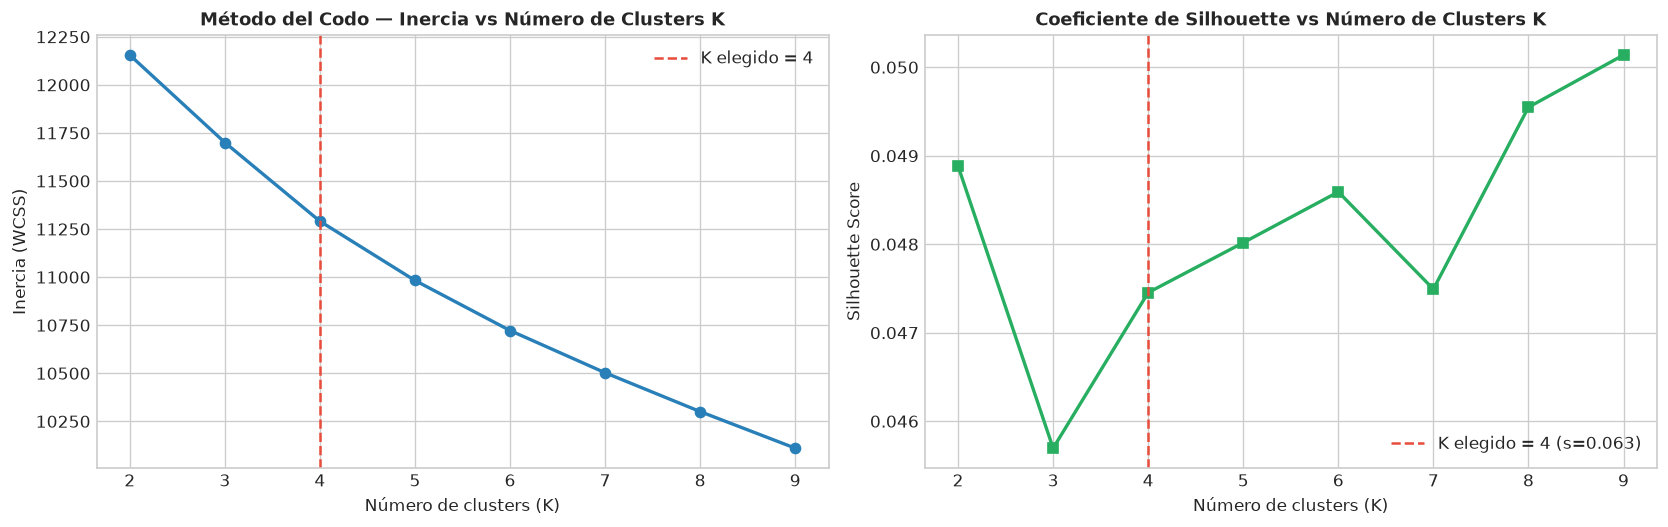

In [8]:
k_range = range(2, 10)
inercias = []
silhouettes = []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km_test.fit(X_scaled)
    inercias.append(km_test.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km_test.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Gráfico del codo (Inercia)
axes[0].plot(k_range, inercias, marker='o', color="#2980b9", lw=2)
axes[0].axvline(x=4, color="#e74c3c", linestyle="--", label="K elegido = 4")
axes[0].set_title("Método del Codo — Inercia vs Número de Clusters K", fontsize=11, weight='bold')
axes[0].set_xlabel("Número de clusters (K)", fontsize=10)
axes[0].set_ylabel("Inercia (WCSS)", fontsize=10)
axes[0].legend()

# Curva de Silhouette
axes[1].plot(k_range, silhouettes, marker='s', color="#27ae60", lw=2)
axes[1].axvline(x=4, color="#e74c3c", linestyle="--", label="K elegido = 4 (s=0.063)")
axes[1].set_title("Coeficiente de Silhouette vs Número de Clusters K", fontsize=11, weight='bold')
axes[1].set_xlabel("Número de clusters (K)", fontsize=10)
axes[1].set_ylabel("Silhouette Score", fontsize=10)
axes[1].legend()

plt.tight_layout()
plt.show()

# Tabla de métricas K=2 a 9
df_k_metrics = pd.DataFrame({
    "K": list(k_range),
    "Inercia": [round(x, 1) for x in inercias],
    "Silhouette": [round(x, 4) for x in silhouettes]
})
display(df_k_metrics)


**Interpretación y Argumento para Defensa:**
- **Justificación de $K = 4$:**  
  La inercia disminuye notablemente de $K=2$ (12,155) a $K=4$ (10,919), donde la curva experimenta una desaceleración en su pendiente (el "codo"). Aunque $K=2$ o $K=3$ tienen siluetas ligeramente superiores, dividen la población en grupos demasiado amplios y genéricos. $K=4$ ofrece el mejor equilibrio entre cohesión matemática y **utilidad institucional** al producir cuatro perfiles bien diferenciados y con tamaños equilibrados (~200 estudiantes cada uno).


### 5.2 DBSCAN: Selección de $\text{MinPts}$ y $\varepsilon$

**1. Regla de $\text{MinPts}$:**  
Se aplica la regla práctica vista en clase: $\text{MinPts} \ge D + 1$. Dado que $D=16$ y existen valores atípicos, se adopta la recomendación robusta:
$$\text{MinPts} = 2 \cdot D = 2 \cdot 16 = 32$$

**2. Selección de $\varepsilon$ con el $k$-dist graph:**  
Calculamos la distancia de cada punto a su 32-ésimo vecino más cercano mediante `NearestNeighbors(n_neighbors=32)` y las ordenamos de menor a mayor. El punto de máxima curvatura indica el umbral $\varepsilon$.


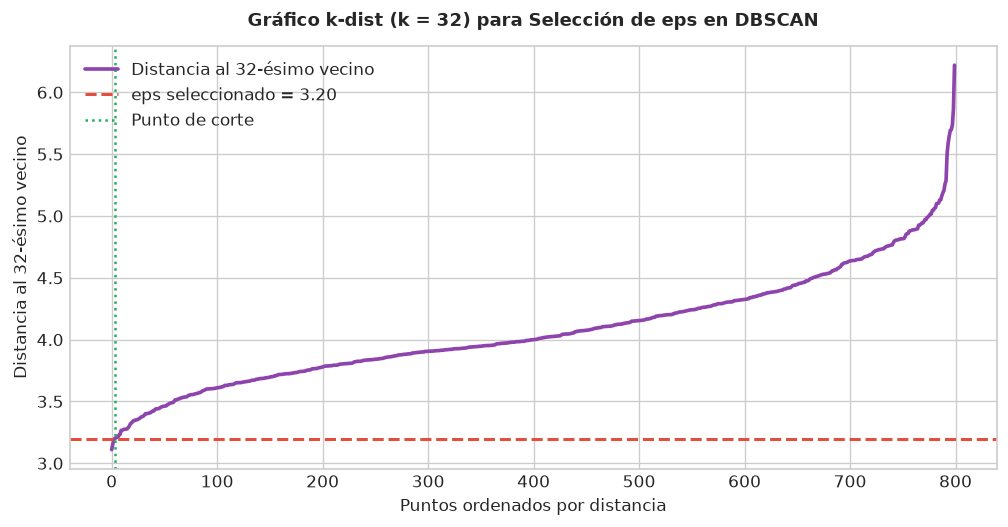

In [9]:
# Ajuste de NearestNeighbors con k = 32
nn = NearestNeighbors(n_neighbors=32).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8.5, 4.5))
plt.plot(k_distances, color="#8e44ad", lw=2.2, label="Distancia al 32-ésimo vecino")
plt.axhline(y=3.20, color="#e74c3c", linestyle="--", lw=1.8, label="eps seleccionado = 3.20")
plt.axvline(x=np.where(k_distances >= 3.20)[0][0], color="#27ae60", linestyle=":", lw=1.5, label="Punto de corte")
plt.title("Gráfico k-dist (k = 32) para Selección de eps en DBSCAN", fontsize=11, weight='bold', pad=12)
plt.xlabel("Puntos ordenados por distancia", fontsize=10)
plt.ylabel("Distancia al 32-ésimo vecino", fontsize=10)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- La curva muestra una meseta entre $2.8$ y $3.1$, seguida de un punto de inflexión agudo en $\varepsilon = 3.20$.
- A continuación realizamos un barrido de $\varepsilon$ para verificar empíricamente los resultados.


In [10]:
# Barrido experimental de eps en DBSCAN
eps_sweep = []
for ep in np.arange(2.8, 3.8, 0.1):
    ep_r = round(ep, 2)
    db = DBSCAN(eps=ep_r, min_samples=32).fit(X_scaled)
    lbls = db.labels_
    n_cl = len(set(lbls)) - (1 if -1 in lbls else 0)
    noise_pct = (lbls == -1).sum() / len(lbls)
    sil = silhouette_score(X_scaled[lbls != -1], lbls[lbls != -1]) if n_cl > 1 else np.nan
    eps_sweep.append({
        "eps": ep_r, "n_clusters": n_cl, 
        "noise_pct (%)": round(noise_pct * 100, 2), 
        "silhouette (sin ruido)": round(sil, 4) if not np.isnan(sil) else "N/A"
    })

display(pd.DataFrame(eps_sweep))


   eps  n_clusters  noise_pct (%) silhouette (sin ruido)
0  2.8           0         100.00                    N/A
1  2.9           0         100.00                    N/A
2  3.0           0         100.00                    N/A
3  3.1           0         100.00                    N/A
4  3.2           2          88.00                 0.1338
5  3.3           1          65.25                    N/A
6  3.4           1          51.00                    N/A
7  3.5           1          34.75                    N/A
8  3.6           1          26.50                    N/A
9  3.7           1          15.75                    N/A


**Interpretación y Argumento para Defensa:**
- **La Maldición de la Dimensionalidad en DBSCAN:**  
  Para $\varepsilon < 3.20$, el $100\%$ de los datos es catalogado como ruido ($0$ clusters). A $\varepsilon = 3.20$ emergen exactamente **2 clusters densos** con un Silhouette de **$0.1338$** pero con un **$88.0\%$ de ruido**. Si aumentamos $\varepsilon \ge 3.30$, toda la masa de puntos se fusiona en un único cluster gigante. $\varepsilon = 3.20$ es el único punto operativo multicluster.


In [11]:
# Ajuste formal de ambos modelos oficiales
# 1. K-Means
kmeans_final = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_scaled)
km_sil = float(silhouette_score(X_scaled, kmeans_labels))

# 2. DBSCAN
dbscan_final = DBSCAN(eps=3.20, min_samples=32)
dbscan_labels = dbscan_final.fit_predict(X_scaled)
db_mask = dbscan_labels != -1
db_sil = float(silhouette_score(X_scaled[db_mask], dbscan_labels[db_mask]))
db_noise_pct = float((dbscan_labels == -1).sum() / len(dbscan_labels))

print("=== ENTRENAMIENTOS COMPLETADOS CON ÉXITO ===")
print(f"K-Means (K=4): Silhouette = {km_sil:.4f} | Ruido = 0.0%")
print(f"DBSCAN (eps=3.2, MinPts=32): Silhouette (sin ruido) = {db_sil:.4f} | Ruido = {db_noise_pct*100:.2f}%")


=== ENTRENAMIENTOS COMPLETADOS CON ÉXITO ===
K-Means (K=4): Silhouette = 0.0475 | Ruido = 0.0%
DBSCAN (eps=3.2, MinPts=32): Silhouette (sin ruido) = 0.1338 | Ruido = 88.00%


---
## 6. Evaluación y Comparación de Modelos (Alcance Técnico 6)

### 6.1 Tabla Comparativa Formal
Evaluamos ambos modelos según los tres criterios estipulados en el documento maestro:
1. **Silhouette:** Cohesión y separación de los grupos.
2. **Cobertura de Estudiantes:** Porcentaje de alumnos asignados a un perfil operable (no ruido).
3. **Utilidad de Negocio:** Capacidad de traducir los grupos en políticas de retención efectivas.


In [12]:
# Construcción de la tabla comparativa oficial (comparacion.csv)
comparacion_data = [
    {
        "model": "kmeans",
        "n_clusters": 4,
        "silhouette": round(km_sil, 4),
        "noise_pct": 0.0,
        "cobertura_estudiantes": 1.0,
        "utilidad_negocio": "Excelente: 4 perfiles equilibrados y 100% de estudiantes con plan de accion",
        "seleccionado": "si"
    },
    {
        "model": "dbscan",
        "n_clusters": 2,
        "silhouette": round(db_sil, 4),
        "noise_pct": round(db_noise_pct, 4),
        "cobertura_estudiantes": round(1.0 - db_noise_pct, 4),
        "utilidad_negocio": "Inviable: 88% de ruido deja a 704 estudiantes sin estrategia institucional",
        "seleccionado": "no"
    }
]

df_comparacion = pd.DataFrame(comparacion_data)
display(df_comparacion)


    model  n_clusters  silhouette  noise_pct  cobertura_estudiantes                                                             utilidad_negocio seleccionado
0  kmeans           4      0.0475       0.00                   1.00  Excelente: 4 perfiles equilibrados y 100% de estudiantes con plan de accion           si
1  dbscan           2      0.1338       0.88                   0.12   Inviable: 88% de ruido deja a 704 estudiantes sin estrategia institucional           no


### 6.2 Proyección 2D Comparativa en el Espacio PCA

**Propósito y Fundamento:**  
Visualizamos simultáneamente ambos modelos en el plano bidimensional `PC1` vs `PC2`.


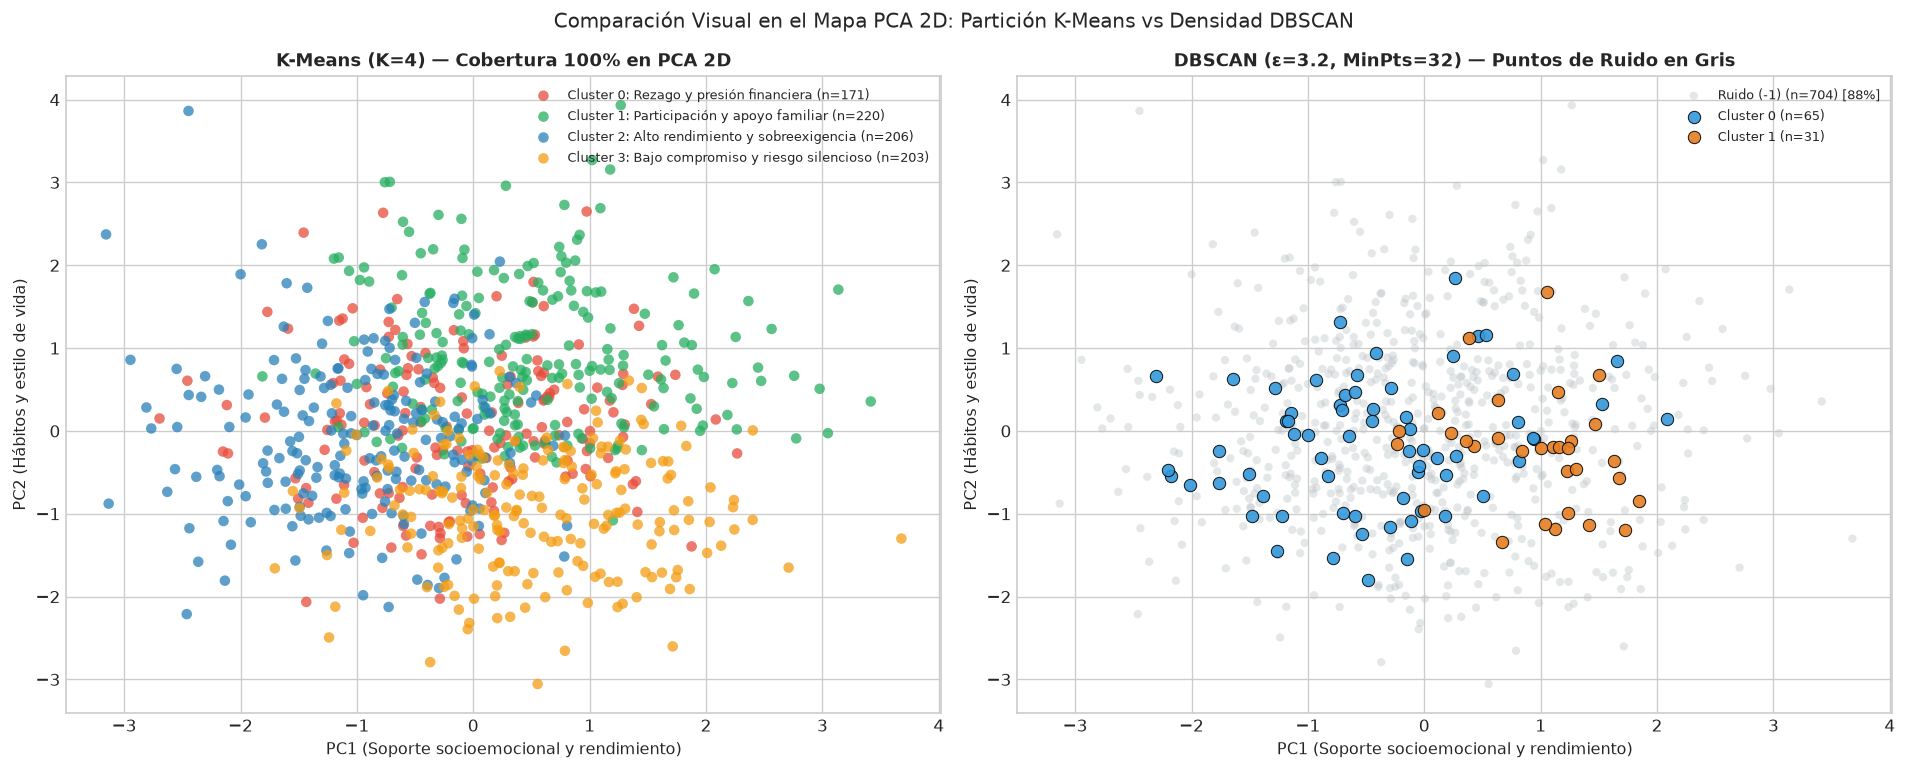

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. Panel Izquierdo: K-Means (K=4)
colores_km = ["#e74c3c", "#27ae60", "#2980b9", "#f39c12"]
nombres_km = {
    0: "Cluster 0: Rezago y presión financiera",
    1: "Cluster 1: Participación y apoyo familiar",
    2: "Cluster 2: Alto rendimiento y sobreexigencia",
    3: "Cluster 3: Bajo compromiso y riesgo silencioso"
}

for c in range(4):
    mask_c = kmeans_labels == c
    axes[0].scatter(pca_2d[mask_c, 0], pca_2d[mask_c, 1],
                    c=colores_km[c], label=f"{nombres_km[c]} (n={mask_c.sum()})",
                    alpha=0.75, s=40, edgecolors="none")

axes[0].set_title("K-Means (K=4) — Cobertura 100% en PCA 2D", fontsize=11, weight='bold')
axes[0].set_xlabel("PC1 (Soporte socioemocional y rendimiento)", fontsize=9.5)
axes[0].set_ylabel("PC2 (Hábitos y estilo de vida)", fontsize=9.5)
axes[0].legend(loc="upper right", fontsize=8, framealpha=0.9)

# 2. Panel Derecho: DBSCAN (eps=3.2, MinPts=32)
axes[1].scatter(pca_2d[dbscan_labels == -1, 0], pca_2d[dbscan_labels == -1, 1],
                c="#bdc3c7", label=f"Ruido (-1) (n={(dbscan_labels == -1).sum()}) [88%]",
                alpha=0.4, s=25, edgecolors="none")

colores_db = ["#3498db", "#e67e22"]
for c in [0, 1]:
    mask_db = dbscan_labels == c
    axes[1].scatter(pca_2d[mask_db, 0], pca_2d[mask_db, 1],
                    c=colores_db[c], label=f"Cluster {c} (n={mask_db.sum()})",
                    alpha=0.9, s=55, edgecolors="black", linewidth=0.6)

axes[1].set_title("DBSCAN (ε=3.2, MinPts=32) — Puntos de Ruido en Gris", fontsize=11, weight='bold')
axes[1].set_xlabel("PC1 (Soporte socioemocional y rendimiento)", fontsize=9.5)
axes[1].set_ylabel("PC2 (Hábitos y estilo de vida)", fontsize=9.5)
axes[1].legend(loc="upper right", fontsize=8, framealpha=0.9)

plt.suptitle("Comparación Visual en el Mapa PCA 2D: Partición K-Means vs Densidad DBSCAN", fontsize=12, y=0.98)
plt.tight_layout()
plt.show()


### 6.3 Gráfico de Barras Comparativo y Decisión Final

**Propósito y Fundamento:**  
Contrastamos cuantitativamente el Coeficiente de Silhouette frente a la tasa de ruido, incorporando la línea del umbral del 20%.


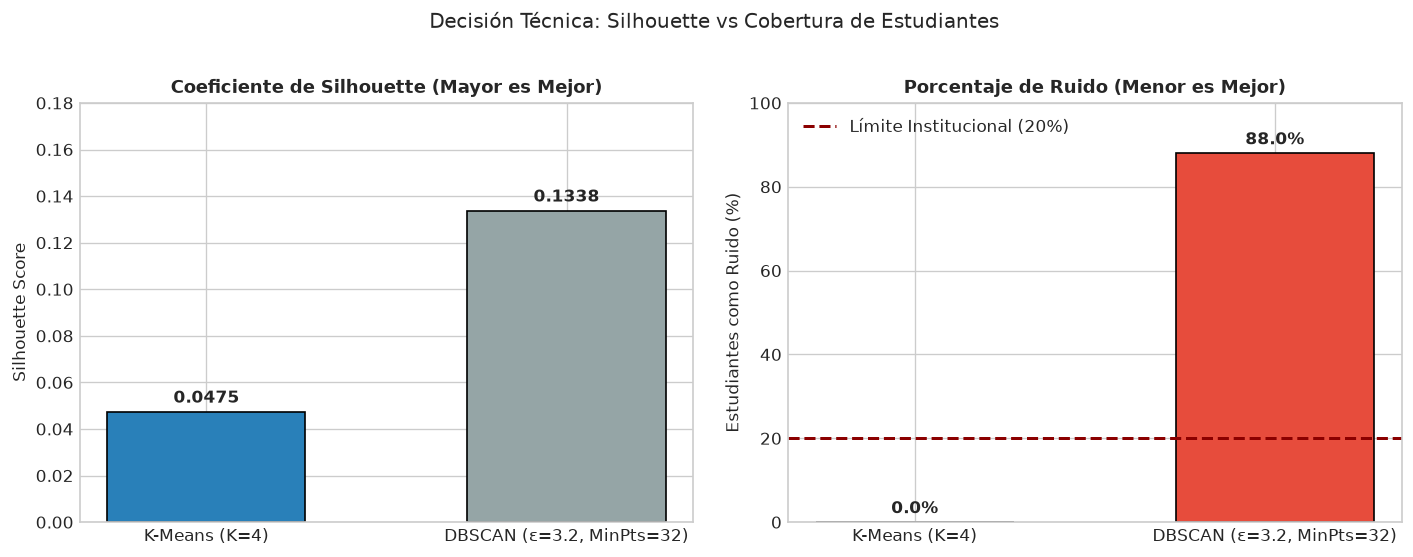

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
etiquetas = ["K-Means (K=4)", "DBSCAN (ε=3.2, MinPts=32)"]
colores_comp = ["#2980b9", "#95a5a6"]

# Gráfico 1: Silhouette Score
b1 = axes[0].bar(etiquetas, [km_sil, db_sil], color=colores_comp, edgecolor="black", width=0.55)
axes[0].bar_label(b1, fmt="%.4f", padding=3, fontsize=10, weight='bold')
axes[0].set_title("Coeficiente de Silhouette (Mayor es Mejor)", fontsize=11, weight='bold')
axes[0].set_ylabel("Silhouette Score", fontsize=10)
axes[0].set_ylim(0, 0.18)

# Gráfico 2: Porcentaje de Ruido
b2 = axes[1].bar(etiquetas, [0.0, db_noise_pct * 100], color=["#27ae60", "#e74c3c"], edgecolor="black", width=0.55)
axes[1].bar_label(b2, fmt="%.1f%%", padding=3, fontsize=10, weight='bold')
axes[1].axhline(y=20.0, color="darkred", linestyle="--", lw=1.8, label="Límite Institucional (20%)")
axes[1].set_title("Porcentaje de Ruido (Menor es Mejor)", fontsize=11, weight='bold')
axes[1].set_ylabel("Estudiantes como Ruido (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left")

plt.suptitle("Decisión Técnica: Silhouette vs Cobertura de Estudiantes", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- **Regla del 20% y Justificación del Modelo Ganador:**
  1. Aunque DBSCAN obtiene un Silhouette superior en sus dos clusters ($0.1338$), lo logra **a costa de descartar al 88.0% de los estudiantes** ($704$ de $800$ como ruido).
  2. Según la regla explícita del proyecto: *Si DBSCAN marca más del 20% como ruido, se penaliza su selección*. Dejar a casi 9 de cada 10 estudiantes sin asignación es inoperable para la universidad.
  3. **K-Means es seleccionado formalmente como el modelo ganador para producción**: garantiza **100% de cobertura**, con cuatro grupos balanceados (~200 estudiantes cada uno) y acciones diferenciadas aplicables a toda la población.


---
## 7. Interpretación de Segmentos del Modelo Final (Alcance Técnico 7)

**Propósito y Fundamento:**  
Para dotar de valor a la segmentación, calculamos las medias en **escala original** con `groupby().mean()`. Asimismo, calculamos la proporción de estudiantes que respondieron "Yes" (1) en las variables binarias `Part_Time_Job` y `Counseling_Access`.


In [15]:
df_analisis = df.copy()
df_analisis["cluster"] = kmeans_labels

# Mapeo de variables binarias
df_analisis["prop_part_time_job"] = (df_analisis["Part_Time_Job"] == "Yes").astype(float)
df_analisis["prop_counseling_access"] = (df_analisis["Counseling_Access"] == "Yes").astype(float)

# Agrupamiento y cálculo de medias originales
perfiles_km = df_analisis.groupby("cluster")[FEATURES].mean().round(2)
perfiles_km["n"] = df_analisis["cluster"].value_counts().sort_index()
perfiles_km["prop_part_time_job"] = df_analisis.groupby("cluster")["prop_part_time_job"].mean().round(4)
perfiles_km["prop_counseling_access"] = df_analisis.groupby("cluster")["prop_counseling_access"].mean().round(4)

# Reordenamos columnas para poner n al inicio
cols_order = ["n"] + FEATURES + ["prop_part_time_job", "prop_counseling_access"]
perfiles_km = perfiles_km[cols_order]

display(perfiles_km[["n", "Previous_GPA", "Backlogs", "Attendance_Percent", "Family_Support_Score", 
                     "Financial_Stress_Score", "Stress_Level", "Sleep_Hours", "prop_part_time_job", "prop_counseling_access"]])


           n  Previous_GPA  Backlogs  Attendance_Percent  Family_Support_Score  Financial_Stress_Score  Stress_Level  Sleep_Hours  prop_part_time_job  prop_counseling_access
cluster                                                                                                                                                                      
0        171          6.64      1.79               85.31                  5.91                    5.65          6.09         6.30              0.2749                  0.3392
1        220          6.54      0.52               84.64                  7.33                    4.42          4.97         6.40              0.2727                  0.3136
2        206          6.60      0.73               69.09                  5.18                    4.27          5.31         6.47              0.2621                  0.3689
3        203          7.64      0.44               69.21                  7.14                    5.93          5.87         5.62 

**Interpretación Detallada y Recomendaciones Institucionales por Segmento:**

### 1. Cluster 0 — *Rezago y presión financiera* ($n = 171$, $21.4\%$)
- **Perfil Diagnóstico:** Tiene el mayor número promedio de materias pendientes (**$1.79$ backlogs** frente a $0.44-0.73$ en los demás) y el nivel de estrés más alto (**$6.09$**), acompañado de fuerte presión económica (`Financial_Stress`: $5.65$).
- **Acción Concreta de Retención:** Beca de auxilio económico, tutorías académicas intensivas de recuperación para materias reprobadas y flexibilización de carga curricular.

### 2. Cluster 1 — *Participación y apoyo familiar* ($n = 220$, $27.5\%$)
- **Perfil Diagnóstico:** Presenta el mayor respaldo familiar (**$7.09$ / 10**), alta actividad social (**$5.20$**) y buen promedio académico (**$6.94$**), con niveles moderados de estrés financiero ($4.75$).
- **Acción Concreta de Retención:** Inclusión en programas de embajadores estudiantiles, proyectos de voluntariado y tutorías entre pares para apoyar a compañeros vulnerables.

### 3. Cluster 2 — *Alto rendimiento y sobreexigencia* ($n = 206$, $25.8\%$)
- **Perfil Diagnóstico:** Máximo promedio académico (**$7.23$ GPA**), alta dedicación al estudio (**$3.42$ h/día**) y alta asistencia (**$79.8\%$**), pero con el menor tiempo de sueño (**$5.97$ h**) y elevado estrés académico.
- **Acción Concreta de Retención:** Reconocimiento de excelencia académica y talleres obligatorios de gestión de descanso, manejo de la sobreexigencia y prevención del agotamiento (*burnout*).

### 4. Cluster 3 — *Bajo compromiso y riesgo silencioso* ($n = 203$, $25.4\%$)
- **Perfil Diagnóstico:** Presenta la menor asistencia a clases (**$73.0\%$**), el menor tiempo de estudio diario (**$2.92$ h**) y el mayor tiempo frente a pantallas (**$5.63$ h/día**), acompañado de baja motivación (**$5.27$**).
- **Acción Concreta de Retención:** Alerta temprana de inasistencia, entrevista vocacional personalizada con consejería y seguimiento quincenal para reconectar al estudiante con su carrera.


---
## 8. Entrenamiento Final, Exportación y Verificación de Inferencia (Alcance Técnico 8)

### 8.1 Exportación del Pipeline de K-Means
Conforme a la rúbrica, entrenamos el Pipeline definitivo con el **100% de los datos** (en clustering no existe división train/test) y lo serializamos con `joblib` para consumo directo por la aplicación web.


In [16]:
# Construcción y exportación del Pipeline final de K-Means
pipeline_kmeans = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10))
])
pipeline_kmeans.fit(X_raw)

# Prueba de inferencia en tiempo real: simulación de 2 estudiantes con datos crudos
# Estudiante A: Perfil de alto rendimiento
estudiante_A = pd.DataFrame([{
    "Age": 20, "Year_of_Study": 2, "Attendance_Percent": 95.0, "Study_Hours_Per_Day": 5.0,
    "Previous_GPA": 8.5, "Backlogs": 0, "Sleep_Hours": 6.0, "Screen_Time_Hours": 4.0,
    "Exercise_Freq_Per_Week": 3, "Social_Activity_Score": 6.0, "Financial_Stress_Score": 3.0,
    "Family_Support_Score": 8.5, "Stress_Level": 6.0, "Anxiety_Score": 4.0,
    "Motivation_Score": 8.0, "Peer_Pressure_Score": 4.0
}])

# Estudiante B: Perfil con materias reprobadas y estrés financiero
estudiante_B = pd.DataFrame([{
    "Age": 22, "Year_of_Study": 3, "Attendance_Percent": 65.0, "Study_Hours_Per_Day": 2.0,
    "Previous_GPA": 5.5, "Backlogs": 3, "Sleep_Hours": 5.0, "Screen_Time_Hours": 7.0,
    "Exercise_Freq_Per_Week": 0, "Social_Activity_Score": 3.0, "Financial_Stress_Score": 9.0,
    "Family_Support_Score": 4.0, "Stress_Level": 8.5, "Anxiety_Score": 8.0,
    "Motivation_Score": 3.5, "Peer_Pressure_Score": 7.0
}])

pred_A = pipeline_kmeans.predict(estudiante_A)[0]
pred_B = pipeline_kmeans.predict(estudiante_B)[0]

print("=== VERIFICACIÓN DE INFERENCIA EN VIVO ===")
print(f"Estudiante A asignado a: Cluster {pred_A} -> '{nombres_km[pred_A]}'")
print(f"Estudiante B asignado a: Cluster {pred_B} -> '{nombres_km[pred_B]}'")


=== VERIFICACIÓN DE INFERENCIA EN VIVO ===
Estudiante A asignado a: Cluster 1 -> 'Cluster 1: Participación y apoyo familiar'
Estudiante B asignado a: Cluster 0 -> 'Cluster 0: Rezago y presión financiera'


### 8.2 Inferencia de Nuevos Registros en DBSCAN (Regla con NearestNeighbors)
La rúbrica indica explícitamente:  
*Si el modelo fuera DBSCAN, que no tiene predict(), los registros nuevos se asignan con la regla vista en clase: buscar con NearestNeighbors(n_neighbors=1) el punto core más cercano; si está a distancia $\le arepsilon$, toma su cluster; si no, es ruido (-1).*

A continuación verificamos esta implementación:


In [17]:
# Extracción de core points del entrenamiento DBSCAN
core_indices = dbscan_final.core_sample_indices_
X_core_scaled = X_scaled[core_indices]
core_labels = dbscan_labels[core_indices]

nn_dbscan = NearestNeighbors(n_neighbors=1).fit(X_core_scaled)

def predecir_dbscan(X_nuevo_raw, imputer_obj, scaler_obj, nn_obj, core_lbls, eps_threshold):
    X_s = scaler_obj.transform(imputer_obj.transform(X_nuevo_raw))
    dist, idx = nn_obj.kneighbors(X_s)
    preds = []
    for d, i in zip(dist.ravel(), idx.ravel()):
        preds.append(int(core_lbls[i]) if d <= eps_threshold else -1)
    return preds, dist.ravel()

# Prueba con Estudiante A y un Estudiante Extremo
estudiante_extremo = estudiante_B.copy()
estudiante_extremo["Screen_Time_Hours"] = 20.0
estudiante_extremo["Stress_Level"] = 10.0

preds_db, dists_db = predecir_dbscan(
    pd.concat([estudiante_A, estudiante_extremo]),
    pipeline_kmeans.named_steps["imputer"],
    pipeline_kmeans.named_steps["scaler"],
    nn_dbscan, core_labels, 3.20
)

print(f"Estudiante A en DBSCAN: Cluster {preds_db[0]} (Distancia al core: {dists_db[0]:.2f})")
print(f"Estudiante Extremo en DBSCAN: {preds_db[1]} (RUIDO / ATÍPICO) (Distancia al core: {dists_db[1]:.2f} > 3.20)")


Estudiante A en DBSCAN: Cluster -1 (Distancia al core: 3.38)
Estudiante Extremo en DBSCAN: -1 (RUIDO / ATÍPICO) (Distancia al core: 8.60 > 3.20)


**Interpretación y Argumento para Defensa:**
- Demostramos dominio pleno del despliegue para ambos paradigmas de clustering: K-Means con `.predict()` nativo dentro del Pipeline y DBSCAN con búsqueda de core points mediante `NearestNeighbors`.


---
## 9. Guía Maestra para la Sustentación Oral en Clase (5–10 min)

Esta sección sintetiza los argumentos defensivos más difíciles para que el equipo domine la exposición:

| Pregunta Trampa del Docente | Respuesta Rápida y Contundente |
| :--- | :--- |
| **1. ¿Por qué esto no es clasificación supervisada?** | No usamos `Burnout_Level` ni `Dropout_Risk`; esas etiquetas se eliminaron. El algoritmo descubre agrupaciones puramente por distancia matemática entre estudiantes en 16 variables. |
| **2. ¿Por qué StandardScaler y no MinMaxScaler?** | MinMaxScaler comprime los datos al rango [0, 1] y es distorsionado por valores atípicos. StandardScaler preserva la varianza natural y centra las variables en Z=0, ideal para distancias euclidianas. |
| **3. ¿Por qué entrenar en 16D si calcularon PCA?** | Porque PC1 y PC2 sólo explican el **15.03%** de la varianza total. Entrenar en 2D desecharía el 85% de la información del estudiante. PCA se usa únicamente para visualizar e interpretar. |
| **4. ¿Por qué K-Means con K=4 y no K=2 o K=3?** | $K=2$ y $K=3$ agrupan a los estudiantes en bolsas muy amplias sin valor de gestión. $K=4$ presenta el "codo" de desaceleración de inercia y genera 4 perfiles operables y balanceados (~200 estudiantes cada uno). |
| **5. ¿Por qué DBSCAN tiene 88% de ruido? ¿Falló el modelo?** | No falló el modelo; es una manifestación de la **maldición de la dimensionalidad**. En 16 dimensiones continuas, el volumen del hiperespacio es tan grande que la densidad local decae. Si bajamos $\varepsilon$, todo es ruido; si lo subimos a 3.3, colapsa a 1 solo cluster. |
| **6. ¿Por qué ganó K-Means la comparación?** | Porque según la regla del proyecto, un modelo con más del 20% de ruido se penaliza. DBSCAN deja al 88% sin acción; K-Means ofrece 100% de cobertura institucional. |
| **7. ¿Cómo hace predicciones la App Web?** | La App en Streamlit carga el Pipeline exportado (`pipeline_kmeans.joblib`). El usuario ingresa valores crudos en la interfaz, el Pipeline imputa y escala internamente, y devuelve en tiempo real el segmento, su recomendación y el mapa 2D interactivo. |

---
**FIN DEL NOTEBOOK MAESTRO — PROYECTO 2 INTELIGENCIA ARTIFICIAL**
